In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [30]:
ruta = r"C:\Users\lleid\OneDrive\Documentos\UNIVERSIDAD\septimo\GrandesBasesdeDatosl\Amazon.xlsx"
amazon = pd.read_excel(ruta, index_col=0)   # la columna de nombres queda como índice
amazon.head()

,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas
Adam,205,3,345,235,24,23,26,21,17
Anna,9,15,315,33,25,4,42,215,28
Bernard,17,26,285,3,43,27,41,26,33
Edward,135,5,355,295,18,23,39,195,17
Emilia,3,45,48,39,34,46,225,34,43


In [31]:
amazon['Numero Estrellas'].describe() #Variable que quiero pronosticar

count    100.000000
mean      28.220000
std       11.720292
min        1.000000
25%       22.750000
50%       30.000000
75%       36.500000
max       48.000000
Name: Numero Estrellas, dtype: float64

<Axes: >

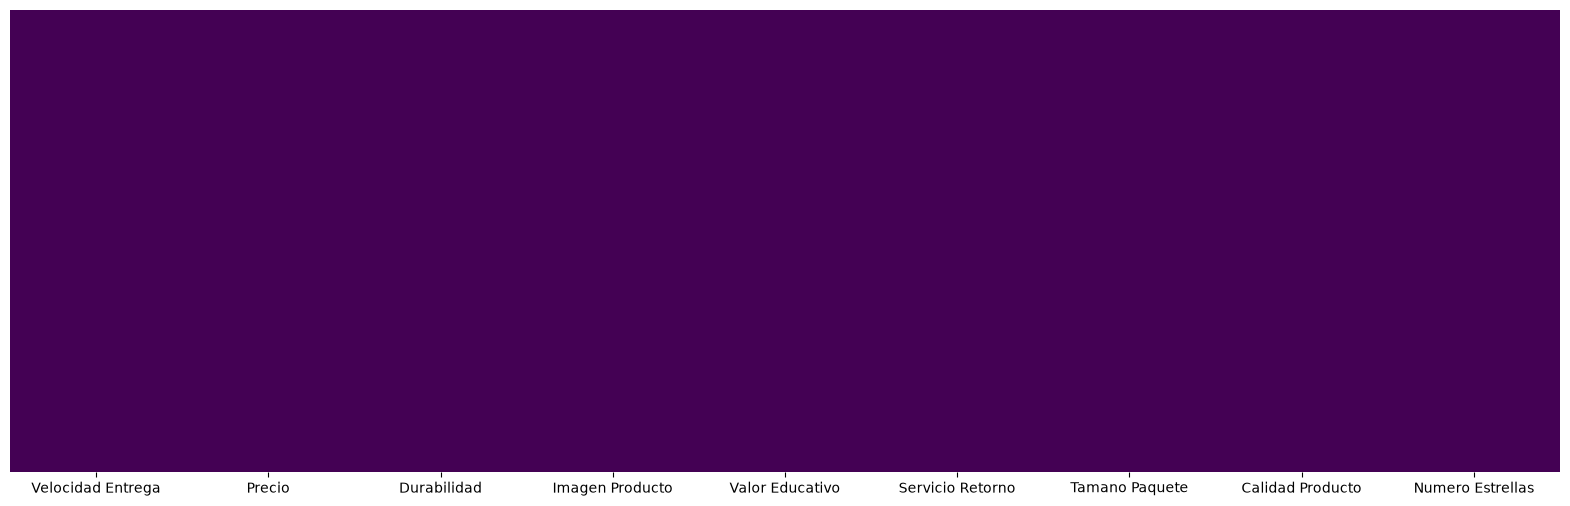

In [32]:
plt.figure(figsize=(20, 6))
sns.heatmap(amazon.isnull(), yticklabels=False, cbar=False, cmap='viridis')

In [33]:
amazon.dropna(inplace=True)
amazon.shape

(100, 9)

In [34]:
X = amazon.drop('Numero Estrellas', axis=1)
y = amazon['Numero Estrellas']

In [35]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = pd.DataFrame(sc.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test = pd.DataFrame(sc.transform(X_test), columns=X.columns, index=X_test.index)

In [36]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

In [37]:
from sklearn.linear_model import LinearRegression
linreg = LinearRegression()
linreg.fit(X_train, y_train)

print("INTERCEPT : ", linreg.intercept_)
print("CO-EFFICIENT : ", linreg.coef_)

y_pred = linreg.predict(X_test)

from sklearn import metrics
print("R-Square Value", metrics.r2_score(y_test, y_pred))
print("mean_absolute_error :", metrics.mean_absolute_error(y_test, y_pred))
print("mean_squared_error : ", metrics.mean_squared_error(y_test, y_pred))
print("root_mean_squared_error : ", np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

INTERCEPT :  5.243563827855223
CO-EFFICIENT :  [ 0.04168531  0.00181023 -0.00453656  0.00625677  0.41960111  0.19191838
  0.01277515  0.01699507]
R-Square Value 0.08251982473231523
mean_absolute_error : 8.642601566366276
mean_squared_error :  133.81346414037483
root_mean_squared_error :  11.567776974871828


In [38]:
from sklearn.linear_model import Ridge

for a in [0, 0.1]:
    ridgereg = Ridge(alpha=a)
    ridgereg.fit(X_train, y_train)
    y_pred = ridgereg.predict(X_test)
    print("alpha =", a)
    print("R-Square Value", metrics.r2_score(y_test, y_pred))
    print("mean_absolute_error :", metrics.mean_absolute_error(y_test, y_pred))
    print("mean_squared_error : ", metrics.mean_squared_error(y_test, y_pred))
    print("root_mean_squared_error : ", np.sqrt(metrics.mean_squared_error(y_test, y_pred)))
    print()

alpha = 0
R-Square Value 0.08251982473231512
mean_absolute_error : 8.642601566366277
mean_squared_error :  133.81346414037486
root_mean_squared_error :  11.56777697487183

alpha = 0.1
R-Square Value 0.0825188526602646
mean_absolute_error : 8.642613814650604
mean_squared_error :  133.81360591600335
root_mean_squared_error :  11.567783102911436



In [39]:
#Ridge con alpha optimo
from sklearn.linear_model import RidgeCV

# malla fina de 100 valores entre 0.001 y 1000, con validación cruzada de 5 particiones
alpha_range = np.logspace(-3, 3, 100)
ridgeregcv = RidgeCV(alphas=alpha_range, scoring='neg_mean_squared_error', cv=5)
ridgeregcv.fit(X_train, y_train)
print("mejor alpha Ridge:", ridgeregcv.alpha_)

y_pred = ridgeregcv.predict(X_test)
print("R-Square Value", metrics.r2_score(y_test, y_pred))
print("mean_absolute_error :", metrics.mean_absolute_error(y_test, y_pred))
print("mean_squared_error : ", metrics.mean_squared_error(y_test, y_pred))
print("root_mean_squared_error : ", np.sqrt(metrics.mean_squared_error(y_test, y_pred)))
print(ridgeregcv.coef_)

mejor alpha Ridge: 1000.0
R-Square Value 0.07136241294968493
mean_absolute_error : 8.750683035206015
mean_squared_error :  135.44076025174726
root_mean_squared_error :  11.637901883576234
[ 0.04252657  0.00321313 -0.00415482  0.00534124  0.371193    0.16978459
  0.01282994  0.01667807]


In [40]:
#Lasso con alpha = 0.001 y 0.01
from sklearn.linear_model import Lasso

for a in [0.001, 0.01]:
    lassoreg = Lasso(alpha=a)
    lassoreg.fit(X_train, y_train)
    y_pred = lassoreg.predict(X_test)
    print("alpha =", a)
    print("coeficientes:", lassoreg.coef_)
    print("R-Square Value", metrics.r2_score(y_test, y_pred))
    print("root_mean_squared_error : ", np.sqrt(metrics.mean_squared_error(y_test, y_pred)))
    print()

alpha = 0.001
coeficientes: [ 0.04168537  0.00181015 -0.00453644  0.00625652  0.41959276  0.19190781
  0.01277526  0.01699486]
R-Square Value 0.08252054215241433
root_mean_squared_error :  11.567772452181556

alpha = 0.01
coeficientes: [ 0.04168594  0.00180948 -0.00453532  0.00625424  0.41951757  0.1918128
  0.01277623  0.01699295]
R-Square Value 0.08252693972328695
root_mean_squared_error :  11.56773212115699



In [41]:
#Lasso con el mejor alpha
from sklearn.linear_model import LassoCV

lassoregcv = LassoCV(alphas=np.logspace(-4, 1, 100), cv=5, random_state=1, max_iter=10000)
lassoregcv.fit(X_train, y_train)
print('alpha : ', lassoregcv.alpha_)
print(lassoregcv.coef_)

y_pred = lassoregcv.predict(X_test)
print("R-Square Value:", metrics.r2_score(y_test, y_pred))
print("mean_absolute_error:", metrics.mean_absolute_error(y_test, y_pred))
print("mean_squared_error:", metrics.mean_squared_error(y_test, y_pred))
print("root_mean_squared_error:", np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

alpha :  6.280291441834247
[ 0.04206818  0.00128963 -0.0037605   0.00467877  0.36728016  0.12548194
  0.01346218  0.01566601]
R-Square Value: 0.08173808991731435
mean_absolute_error: 8.810434305390679
mean_squared_error: 133.92747929454848
root_mean_squared_error: 11.57270406147796


In [42]:
modelos = {"Lineal": linreg, "Ridge (CV)": ridgeregcv, "Lasso (CV)": lassoregcv}
tabla = pd.DataFrame({
    nombre: {
        "R2 train": metrics.r2_score(y_train, m.predict(X_train)),
        "R2 test": metrics.r2_score(y_test, m.predict(X_test)),
        "RMSE test": np.sqrt(metrics.mean_squared_error(y_test, m.predict(X_test))),
    } for nombre, m in modelos.items()
}).T
print(tabla.round(4))

            R2 train  R2 test  RMSE test
Lineal        0.3990   0.0825    11.5678
Ridge (CV)    0.3966   0.0714    11.6379
Lasso (CV)    0.3932   0.0817    11.5727
